# Regression

## Linear Regression

In [1]:
# Linear relationship between independent (input feature) and dependent (target) 
# single input feature is called simple regression
# more than one feature multiple linear regression
# y = wx +b, we have to found w, b
# w is slope or weight and b is intercpt or bias
# Loss function (mean squared error)
# J(w,b) = 1/n(sum (yi - (wxi+b))^2)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
np.random.seed(42)
X = 2*np.random.rand(100,1)
y = 3*X+4+np.random.rand(100,1)

In [4]:
# convert data to dataframe
data = pd.DataFrame({'X': X.flatten(), 'y': y.flatten()})
data

,X,y
0,0.749080,6.278670
1,1.901429,10.340696
2,1.463988,8.706320
3,1.197317,8.100522
4,0.312037,5.843678
...,...,...
95,0.987591,7.311983
96,1.045466,7.862353
97,0.855082,7.462356
98,0.050838,5.039601


Text(0, 0.5, 'y')

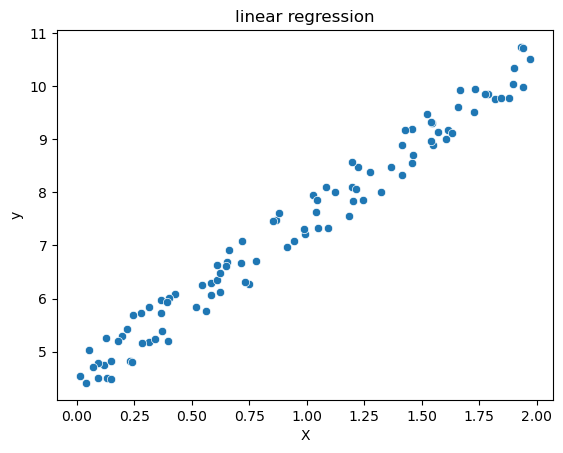

In [5]:
# scatter plot
sns.scatterplot(x = 'X', y = 'y', data=data)
plt.title("linear regression")
plt.xlabel("X")
plt.ylabel("y")

In [6]:
# manual calculation of w and b
x_mean = X.mean()
y_mean = y.mean()

In [7]:

numerator = np.sum((X-x_mean)*(y-y_mean))
denominater = np.sum((X-x_mean)**2)

w = numerator / denominater
b = y_mean -w * x_mean

print(f"Estimated weight : {w: .4f}")
print(f"Estimated bias : {b: .4f}")

Estimated weight :  2.9832
Estimated bias :  4.5136


In [8]:
# prediction
y_pred_manual = w*X + b

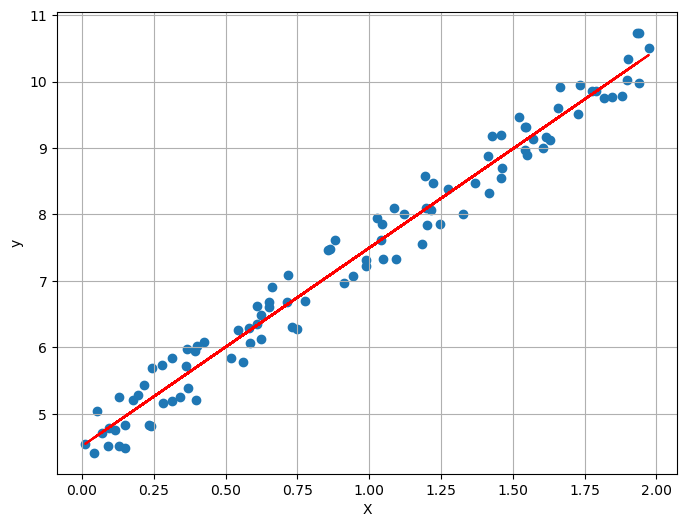

In [9]:
plt.figure(figsize=(8,6))
plt.scatter(X,y, label = 'actual')
plt.plot(X, y_pred_manual, color = 'red', label = 'manual prediction')
plt.xlabel('X')
plt.ylabel('y')
plt.grid()


## linear regression in scikit-learn

In [10]:
from sklearn.linear_model import LinearRegression

In [11]:
# Fit model
model = LinearRegression()
model.fit(X, y)

print(f"sklearn Weight (w): {model.coef_[0][0]:.4f}")
print(f"sklearn bias (b): {model.intercept_[0]:.4f}")
# 
y_pred_sklearn = model.predict(X)

sklearn Weight (w): 2.9832
sklearn bias (b): 4.5136


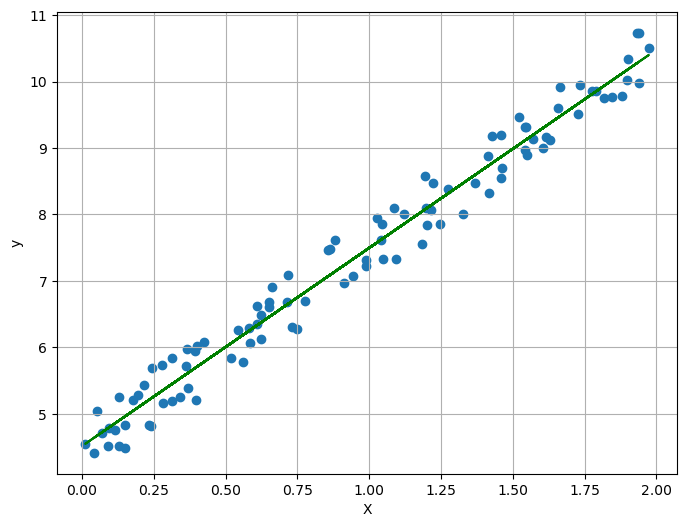

In [12]:
plt.figure(figsize=(8,6))
plt.scatter(X,y, label = 'actual')
plt.plot(X,y_pred_sklearn , color = 'green', label = 'manual prediction')
plt.xlabel('X')
plt.ylabel('y')
plt.grid()

## Evaluation metrices

we evaluate the model using 
Mean squared Error (MSE)

In [13]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y, y_pred_sklearn)
print(f"Mean squared error: {mse: .4f}")

Mean squared error:  0.0850


## Multiple Linear Regression

In [14]:
# y = 3x1 +5x2 + 4+ noise
np.random.seed(42)
x1 = 2*np.random.rand(100,1)
x2 = 2*np.random.rand(100,1)
b_true = 4
w1_true = 3
w2_true = 5
y = 3*x1 + 5*x2+4+np.random.rand(100,1)

In [15]:
# creat multiple features
x1 = 2 * np.random.rand(100,1)
x2 = 3 * np.random.rand(100,1)
b_true = 4
w1_true = 3
w2_true = 5

In [16]:
# y = w1*x1+w2*x2+b+noise
y = w1_true*x1+w2_true*x2+b_true+np.random.randn(100,1)

In [17]:
# combine features into single array
X_multi = np.hstack([x1,x2])
df_multi = pd.DataFrame({'x1':x1.flatten(), 'x2':x2.flatten(), 'y': y.flatten()})
df_multi.head()

,x1,x2,y
0,0.103363,0.309372,6.198704
1,1.062709,2.707659,22.602592
2,1.081270,1.515757,15.773020
3,1.274860,2.479372,19.644538
4,1.452183,0.960149,12.258877


In [18]:
# add columns for biase term
X_b_multi = np.c_[np.ones((100,1)),X_multi] ##shape(100,3)

# w = (XT.X)-1.XT.y
theta_multi = np.linalg.inv(X_b_multi.T.dot(X_b_multi)).dot(X_b_multi.T).dot(y)

b_manual = theta_multi[0][0]
w_manual = theta_multi[1:].flatten()

print(f"Bias (b): {b_manual:.4f}")
print(f"w1: {w_manual[0]:.4f} , w2: {w_manual[1]:.4f}")


Bias (b): 4.4038
w1: 2.5383 , w2: 5.0222


In [19]:
# fit model using sklearn\
model_multi = LinearRegression()
model_multi.fit(X_multi,y)

print(f"sklearn Bias (b): {model_multi.intercept_[0]:.4f}")
print(f"sklearn weights w1 : {model_multi.coef_[0][0]:.4f}, w2: {model_multi.coef_[0][1]:.4f}")

y_pred_sklearn = model.predict(X)

sklearn Bias (b): 4.4038
sklearn weights w1 : 2.5383, w2: 5.0222


In [20]:
## Evaluate model
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y, y_pred_sklearn)
print(f"Mean squared error: {mse: .4f}")

Mean squared error:  84.1108


# Poly nomial regression

In [27]:
np.random.seed(0)
X_poly = 6*np.random.rand(100,1)-3
y_poly = 1 + 0.5* X_poly+1.2*X_poly**2 + np.random.randn(100,1)


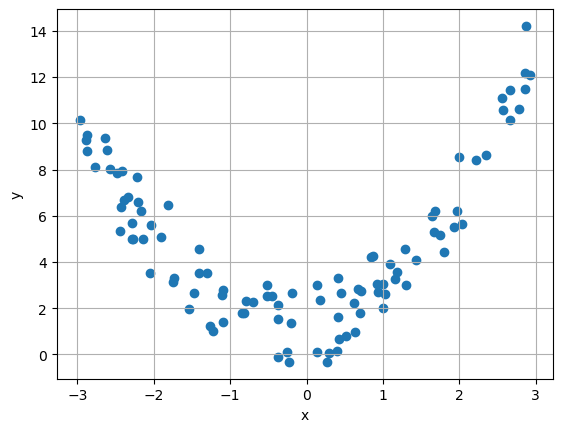

In [28]:
# plot 
plt.scatter(X_poly, y_poly)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.show()

In [29]:
# manualy add x^2 as new feature
X_poly_manual = np.hstack((X_poly, X_poly**2))
X_b_poly = np.c_[np.ones((100,1)), X_poly_manual]

In [30]:
# Closed form solution
theta_poly = np.linalg.inv(X_b_poly.T.dot(X_b_poly)).dot(X_b_poly.T).dot(y_poly)

b_poly = theta_poly[0][0]
w1_poly = theta_poly[1][0]
w2_poly = theta_poly[2][0]

print(f"Bias (b): {b_poly:.4f}")
print(f"weight w1: {w1_poly:.4f}, w2: {w2_poly:.4f}")

Bias (b): 1.3405
weight w1: 0.4791, w2: 1.1498


In [31]:
#
x_plot = np.linspace(-3,3,100).reshape(-1,1)
x_plot_ext = np.hstack((x_plot, x_plot**2))
x_plot_b = np.c_[np.ones((100,1)), x_plot_ext]

y_pred_plot = x_plot_b.dot(theta_poly)

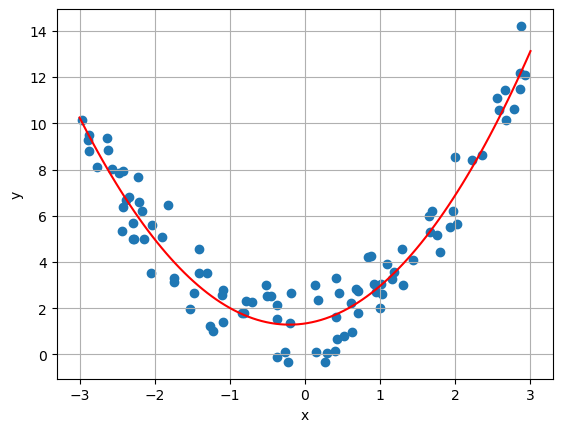

In [32]:
# plot
plt.scatter(X_poly, y_poly, label = "Data")
plt.plot(x_plot, y_pred_plot, color ='r')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()

# Logistic regression